In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# to load dataset from hugging face

from datasets import load_dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
emotion_dataset = load_dataset('dair-ai/emotion')
train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']

test_text = emotion_dataset['test']['text']
test_label = emotion_dataset['test']['label']

In [ ]:
label_names = emotion_dataset['train'].features['label'].names

### create train and test dataframes

In [ ]:
df_train = pd.DataFrame({
    'text' : train_text,
    'label': [label_names[i] for i in train_label]
})

df_test = pd.DataFrame({
    'text' : test_text,
    'label':[label_names[i] for i in test_label]
})

In [ ]:
df_train

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger
...,...,...
15995,i just had a very brief time in the beanbag an...,sadness
15996,i am now turning and i feel pathetic that i am...,sadness
15997,i feel strong and good overall,joy
15998,i feel like this was such a rude comment and i...,anger


In [ ]:
df_train.isnull().sum()

,0
text,0
label,0


# exploratory data analysis (EDA)

In [ ]:
df_train['label'].value_counts().index

Index(['joy', 'sadness', 'anger', 'fear', 'love', 'surprise'], dtype='object', name='label')

<Axes: xlabel='label', ylabel='count'>

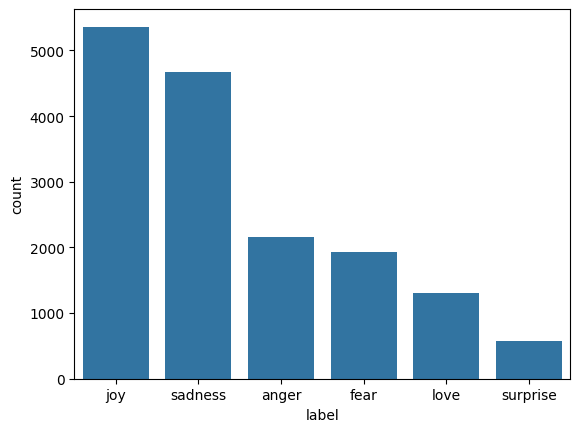

In [ ]:
sns.countplot(x = 'label' , data = df_train,order = df_train['label'].value_counts().index)

Multiclass imbalance issue is IDENTIFIED

#### *PREPROCESSING - USING NLP*

In [ ]:
# tokenize text
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words = 10000

tokenizer = Tokenizer(num_words=max_words,oov_token='<unk>')

In [ ]:
tokenizer.fit_on_texts(df_train['text'])
train_sequence = tokenizer.texts_to_sequences(df_train['text'])
test_sequence = tokenizer.texts_to_sequences(df_test['text'])

padding_train = pad_sequences(train_sequence,maxlen = 50 , padding = 'post' , truncating = 'post')
padding_test = pad_sequences(test_sequence,maxlen = 50 , padding = 'post' , truncating = 'post')

In [ ]:
train_labels = np.array(train_label)
test_labels = np.array(test_label)

num_classes = len(np.unique(train_label))
num_classes

6

In [ ]:
train_labels

array([0, 0, 3, ..., 1, 3, 0], shape=(16000,))

In [ ]:
print(f"Total unique words: ", len(tokenizer.word_index))
print(f"Vocab size: ", tokenizer.num_words)
print(f"Max sequence length: ", padding_train.shape[1])

Total unique words:  15213
Vocab size:  10000
Max sequence length:  50


Handle class imbalance

In [ ]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight = 'balanced',
    classes = np.unique(train_labels),
    y = train_labels
)

class_weight_dict = dict(enumerate(class_weights))

Early stopping

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

earlystopping = EarlyStopping(
    patience = 5,
    monitor = 'val_loss',
    restore_best_weights = True
)

# PHASE - ONE

### Start with RNN

In [ ]:
# simple rnn

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding ,SimpleRNN , Dropout , Dense
from tensorflow.keras.metrics import SparseCategoricalAccuracy

rnn_model = Sequential([
    Embedding(input_dim = max_words,output_dim = 128,input_length = 50),
    SimpleRNN(units = 128 , return_sequences=True),
    Dropout(0.5),
    SimpleRNN(units = 64),
    Dropout(0.5),
    Dense(units = num_classes , activation = 'softmax')
])

rnn_model.compile(optimizer = 'adam' , loss = 'sparse_categorical_crossentropy'
                  , metrics = [SparseCategoricalAccuracy()])



/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
rnn_model.fit(
    padding_train ,
    train_labels,
    validation_data = (padding_test , test_labels),
    epochs = 25,
    batch_size = 32,
    callbacks = [earlystopping],
    class_weight = class_weight_dict
)

Epoch 1/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - loss: 2.0396 - sparse_categorical_accuracy: 0.1641 - val_loss: 1.8359 - val_sparse_categorical_accuracy: 0.1150
Epoch 2/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 1.8765 - sparse_categorical_accuracy: 0.1507 - val_loss: 1.7621 - val_sparse_categorical_accuracy: 0.1195
Epoch 3/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 1.8317 - sparse_categorical_accuracy: 0.1334 - val_loss: 1.7632 - val_sparse_categorical_accuracy: 0.3120
Epoch 4/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 1.8035 - sparse_categorical_accuracy: 0.1362 - val_loss: 1.7773 - val_sparse_categorical_accuracy: 0.1250
Epoch 5/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - loss: 1.8016 - sparse_categorical_accuracy: 0.1343 - val_loss: 1.8407 - val_sparse_categorical_accuracy: 0.0795
Epoch 6/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 1.8028 - sparse_categorical_accuracy: 0.1364 - val_loss: 1.8034 - val_sparse_categorical_accuracy: 0.03

In [ ]:
rnn_loss , rnn_accuracy = rnn_model.evaluate(padding_test , test_labels)

print(f'RNN loss:{rnn_loss}')
print(f'RNN accuracy:{rnn_accuracy}')

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 1.7621 - sparse_categorical_accuracy: 0.1195
RNN loss:1.7620757818222046
RNN accuracy:0.11949999630451202


## Proceed with LSTM

In [ ]:
from tensorflow.keras.layers import LSTM,GRU

lstm_model = Sequential([
    Embedding(input_dim = max_words , output_dim = 128 , input_length = 50),
    LSTM(units = 128 , return_sequences = True),
    Dropout(0.5),
    LSTM(units = 64),
    Dropout(0.5),
    Dense(units = num_classes , activation = 'softmax')
])

lstm_model.compile(optimizer='adam' , loss = 'sparse_categorical_crossentropy' , metrics = [SparseCategoricalAccuracy()])

In [ ]:
lstm_model.fit(
    padding_train,
    train_labels,
    validation_data = (padding_test , test_labels),
    epochs = 25,
    batch_size = 32,
    callbacks = [earlystopping],
    class_weight = class_weight_dict
)

Epoch 1/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - loss: 1.7951 - sparse_categorical_accuracy: 0.1514 - val_loss: 1.7939 - val_sparse_categorical_accuracy: 0.2905
Epoch 2/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 1.7939 - sparse_categorical_accuracy: 0.1701 - val_loss: 1.7999 - val_sparse_categorical_accuracy: 0.0385
Epoch 3/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - loss: 1.7910 - sparse_categorical_accuracy: 0.1738 - val_loss: 1.7767 - val_sparse_categorical_accuracy: 0.2865
Epoch 4/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 1.7912 - sparse_categorical_accuracy: 0.1517 - val_loss: 1.7822 - val_sparse_categorical_accuracy: 0.1370
Epoch 5/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - loss: 1.7471 - sparse_categorical_accuracy: 0.1970 - val_loss: 1.6221 - val_sparse_categorical_accuracy: 0.2670
Epoch 6/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - loss: 1.2869 - sparse_categorical_accuracy: 0.3960 - val_loss: 0.8945 - val_sparse_categorical_accuracy: 0.650

In [ ]:
lstm_loss , lstm_accuracy = lstm_model.evaluate(padding_test , test_labels)

print(f'lstm loss: {lstm_loss}')
print(f'lstm accuracy: {lstm_accuracy}')

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3533 - sparse_categorical_accuracy: 0.9080
lstm loss: 0.3532881736755371
lstm accuracy: 0.9079999923706055


## NOW GPU

In [ ]:
gru_model = Sequential([
    Embedding(input_dim = max_words , output_dim = 128 , input_length = 50),
    GRU(units = 128 , return_sequences = True),
    Dropout(0.5),
    GRU(units = 64),
    Dropout(0.5),
    Dense(units = num_classes , activation = 'softmax')
])

gru_model.compile(optimizer='adam' , loss = 'sparse_categorical_crossentropy' , metrics = [SparseCategoricalAccuracy()])

In [ ]:
gru_model.fit(
    padding_train,
    train_labels,
    validation_data = (padding_test , test_labels),
    epochs = 25,
    batch_size = 32,
    callbacks = [earlystopping],
    class_weight = class_weight_dict
)

Epoch 1/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 11ms/step - loss: 1.7965 - sparse_categorical_accuracy: 0.1632 - val_loss: 1.8311 - val_sparse_categorical_accuracy: 0.0330
Epoch 2/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 11ms/step - loss: 1.7945 - sparse_categorical_accuracy: 0.1489 - val_loss: 1.7932 - val_sparse_categorical_accuracy: 0.0810
Epoch 3/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 15ms/step - loss: 1.7944 - sparse_categorical_accuracy: 0.1480 - val_loss: 1.8113 - val_sparse_categorical_accuracy: 0.0810
Epoch 4/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - loss: 1.7941 - sparse_categorical_accuracy: 0.1628 - val_loss: 1.7788 - val_sparse_categorical_accuracy: 0.3445
Epoch 5/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - loss: 1.7860 - sparse_categorical_accuracy: 0.1674 - val_loss: 1.7940 - val_sparse_categorical_accuracy: 0.0780


In [ ]:
gru_loss , gru_accuracy = gru_model.evaluate(padding_test , test_labels)

print(f'gru loss: {gru_loss}')
print(f'gru accuracy: {gru_accuracy}')

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.8311 - sparse_categorical_accuracy: 0.0330
gru loss: 1.8310508728027344
gru accuracy: 0.032999999821186066


## Phase 1 ranking and selection

Rank all the foundational models and pick the best base cell for phase 2

In [ ]:
result_df = pd.DataFrame({
    'models' : ['RNN','LSTM','GRU'],
    'Loss' : [rnn_loss,lstm_loss,gru_loss],
    'accuracy' : [rnn_accuracy,lstm_accuracy,gru_accuracy]
})

result_df

,models,Loss,accuracy
0,RNN,1.762076,0.1195
1,LSTM,0.353288,0.9080
2,GRU,1.831051,0.0330


LSTM performed very well amaong all the RNNs , but due to it's design , less gates and fewer parameters than lstm we will continue with GRU and if at any case we see that gru is not performing well after the advancement we will pick LSTM then

# Phase 2 - Bidirectional GRU

- #### BI-GRU come with two opposite direction (left - right & right - left)
- #### 300D Embedding
- #### 0.5 dropout regularisation

In [ ]:
from tensorflow.keras.layers import Bidirectional

bigru = Sequential([
    Embedding(input_dim = max_words , output_dim = 300 , input_length = 50),
    Bidirectional(GRU (units = 128 , return_sequences= True)),
    Dropout(0.5),
    Bidirectional(GRU(units = 64)),
    Dropout(0.5),
    Dense(units = num_classes , activation = 'softmax')
])

bigru.compile(optimizer = 'adam' , loss = 'sparse_categorical_crossentropy',metrics = [SparseCategoricalAccuracy()])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [ ]:
bigru.fit(
    padding_train,
    train_labels,
    validation_data = (padding_test , test_labels),
    epochs = 25,
    batch_size = 32,
    callbacks = [earlystopping],
    class_weight = class_weight_dict
)

Epoch 1/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 12s 17ms/step - loss: 0.9949 - sparse_categorical_accuracy: 0.5962 - val_loss: 0.3145 - val_sparse_categorical_accuracy: 0.9000
Epoch 2/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - loss: 0.2306 - sparse_categorical_accuracy: 0.9174 - val_loss: 0.2691 - val_sparse_categorical_accuracy: 0.9080
Epoch 3/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 10s 20ms/step - loss: 0.1359 - sparse_categorical_accuracy: 0.9466 - val_loss: 0.2298 - val_sparse_categorical_accuracy: 0.9200
Epoch 4/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 8s 16ms/step - loss: 0.1177 - sparse_categorical_accuracy: 0.9584 - val_loss: 0.2524 - val_sparse_categorical_accuracy: 0.9185
Epoch 5/25
500/500 ━━━━━━━━━━━━━━━━━━━━ 9s 18ms/step - loss: 0.0855 - sparse_categorical_accuracy: 0.9693 - val_loss: 0.2642 - val_sparse_categorical_accuracy: 0.9150


In [ ]:
bigru_loss , bigru_accuracy = bigru.evaluate(padding_test , test_labels)

print(f'bigru loss : {bigru_loss}')
print(f'bigru accuracy : {bigru_accuracy}')

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.3145 - sparse_categorical_accuracy: 0.9000
bigru loss : 0.31448930501937866
bigru accuracy : 0.8999999761581421


63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step


<Axes: >

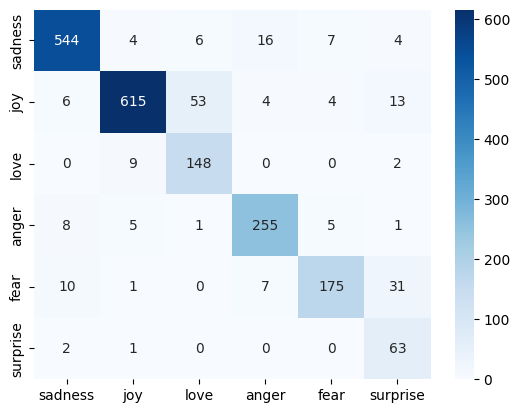

In [ ]:
from sklearn.metrics import confusion_matrix

predictions = np.argmax(bigru.predict(padding_test),axis = 1)

sns.heatmap(confusion_matrix(test_labels , predictions),annot = True,fmt ='d',cmap = 'Blues',xticklabels=label_names,yticklabels=label_names)

In [ ]:
sample_texts = [
    "I can't believe how happy I am right now, this is amazing!",
    "I feel so alone and hopeless today.",
    "I am furious that they cancelled the trip at the last minute.",
    "I feel terrified when walking down dark alleyways alone.",
    "I was shocked and completely surprised by the unexpected gift!"
]

sample_sqnc= tokenizer.texts_to_sequences(sample_texts)
padding_sample = pad_sequences(sample_sqnc , maxlen = 50 , padding='post' , truncating= 'post')
sample_predictions =np.argmax(bigru.predict(padding_sample),axis= 1)

for i in range (len(sample_texts)):
  print(f'text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
text: I can't believe how happy I am right now, this is amazing!
Predicted Emotion: surprise
text: I feel so alone and hopeless today.
Predicted Emotion: sadness
text: I am furious that they cancelled the trip at the last minute.
Predicted Emotion: anger
text: I feel terrified when walking down dark alleyways alone.
Predicted Emotion: fear
text: I was shocked and completely surprised by the unexpected gift!
Predicted Emotion: surprise


In [ ]:
import os
import pickle

folder_name = 'drive/MyDrive/Artifacts'
os.makedirs(folder_name , exist_ok = True)

bigru.save(os.path.join(folder_name , 'bigru.model.keras'))
with open(os.path.join(folder_name , 'tokenizer.pkl'),'wb') as file:
  pickle.dump(tokenizer,file)